# Phase III: K-Nearest Neighbors (KNN) Classification
**Author:** Ahmed Younas — MS Artificial Intelligence, Semester 1  
**Protocol:** Stratified 38 genuine train (+96 training-only synthetic = 134 augmented) vs. 16 untouched genuine holdout records (`SEED=42`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"Environment ready | NumPy {np.__version__}, Pandas {pd.__version__}, Seed={SEED}")

Environment ready | NumPy 2.5.3, Pandas 3.0.6, Seed=42


## 1. Load Leakage-Free Splits & Define Feature Configurations
Compare **Config A (18 atomic features)** and **Config B (14 composite features)**. Target columns (`academic_impact_avg`, `impact_category`, `impact_encoded`, Q6–Q8) are strictly excluded.

In [2]:
current_dir = Path.cwd()
if (current_dir / "data" / "splits").exists():
    data_dir = current_dir / "data" / "splits"
elif (current_dir / "Digital_Device_Usage_Analysis" / "data" / "splits").exists():
    data_dir = current_dir / "Digital_Device_Usage_Analysis" / "data" / "splits"
elif (current_dir / "train_augmented_features.csv").exists():
    data_dir = current_dir
else:
    data_dir = current_dir.parent / "data" / "splits"

df_train_aug = pd.read_csv(data_dir / "train_augmented_features.csv")
df_train_gen = pd.read_csv(data_dir / "genuine_train_features.csv")
df_test = pd.read_csv(data_dir / "genuine_test_features.csv")

config_a = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'daily_device_hours', 'check_frequency',
    'phone_with_family', 'conversation_interruption', 'social_complaints', 'stay_away_difficulty',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]
config_b = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'social_conflict_score', 'digital_dependency_score',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]

forbidden = {'academic_impact_avg', 'impact_category', 'impact_encoded', 'record_id', 'data_source', 'Timestamp'}
assert not forbidden.intersection(config_a) and not forbidden.intersection(config_b)

print(f"Augmented Train: {df_train_aug.shape} | Genuine Train: {df_train_gen.shape} | Genuine Holdout: {df_test.shape}")
print("Holdout class counts:", df_test['impact_category'].value_counts().to_dict())

Augmented Train: (134, 24) | Genuine Train: (38, 24) | Genuine Holdout: (16, 24)
Holdout class counts: {'Moderate Impact': 10, 'High Impact': 4, 'Low Impact': 2}


## 2. Stratified 5-Fold Cross-Validation Grid Search
`StandardScaler` is fitted inside the `Pipeline` per fold. Grid: $K \in \{3,5,7,9,11,13,15\}$, weights $\in \{\text{uniform}, \text{distance}\}$, metric $\in \{\text{euclidean}, \text{manhattan}\}$, scored by Macro F1.

In [3]:
experiments = [
    {'id': 'aug_config_a', 'name': 'Augmented Train (N=134) | Config A (Atomic)', 'train_df': df_train_aug, 'features': config_a, 'color': '#1f77b4'},
    {'id': 'aug_config_b', 'name': 'Augmented Train (N=134) | Config B (Composite)', 'train_df': df_train_aug, 'features': config_b, 'color': '#2ca02c'},
    {'id': 'gen_config_a', 'name': 'Genuine Only Baseline (N=38) | Config A (Atomic)', 'train_df': df_train_gen, 'features': config_a, 'color': '#ff7f0e'},
    {'id': 'gen_config_b', 'name': 'Genuine Only Baseline (N=38) | Config B (Composite)', 'train_df': df_train_gen, 'features': config_b, 'color': '#d62728'}
]

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
trained_models = {}
cv_rows = []

for exp in experiments:
    X_tr = exp['train_df'][exp['features']].values
    y_tr = exp['train_df']['impact_encoded'].values
    pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
    grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1_macro', n_jobs=1)
    grid.fit(X_tr, y_tr)
    trained_models[exp['id']] = {
        'grid': grid, 'best_pipe': grid.best_estimator_, 'best_params': grid.best_params_,
        'best_score': grid.best_score_, 'X_tr': X_tr, 'y_tr': y_tr,
        'features': exp['features'], 'name': exp['name']
    }
    cv_rows.append({
        'Condition': exp['name'], 'N_train': len(X_tr), 'Features': len(exp['features']),
        'Best K': grid.best_params_['knn__n_neighbors'],
        'Weights': grid.best_params_['knn__weights'],
        'Metric': grid.best_params_['knn__metric'],
        'CV Macro F1': round(grid.best_score_, 4)
    })

pd.DataFrame(cv_rows)

,Condition,N_train,Features,Best K,Weights,Metric,CV Macro F1
0,Augmented Train (N=134) | Config A (Atomic),134,18,15,distance,manhattan,0.5976
1,Augmented Train (N=134) | Config B (Composite),134,14,9,distance,euclidean,0.5754
2,Genuine Only Baseline (N=38) | Config A (Atomic),38,18,9,uniform,euclidean,0.3014
3,Genuine Only Baseline (N=38) | Config B (Compo...,38,14,11,uniform,manhattan,0.3231


<cell>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


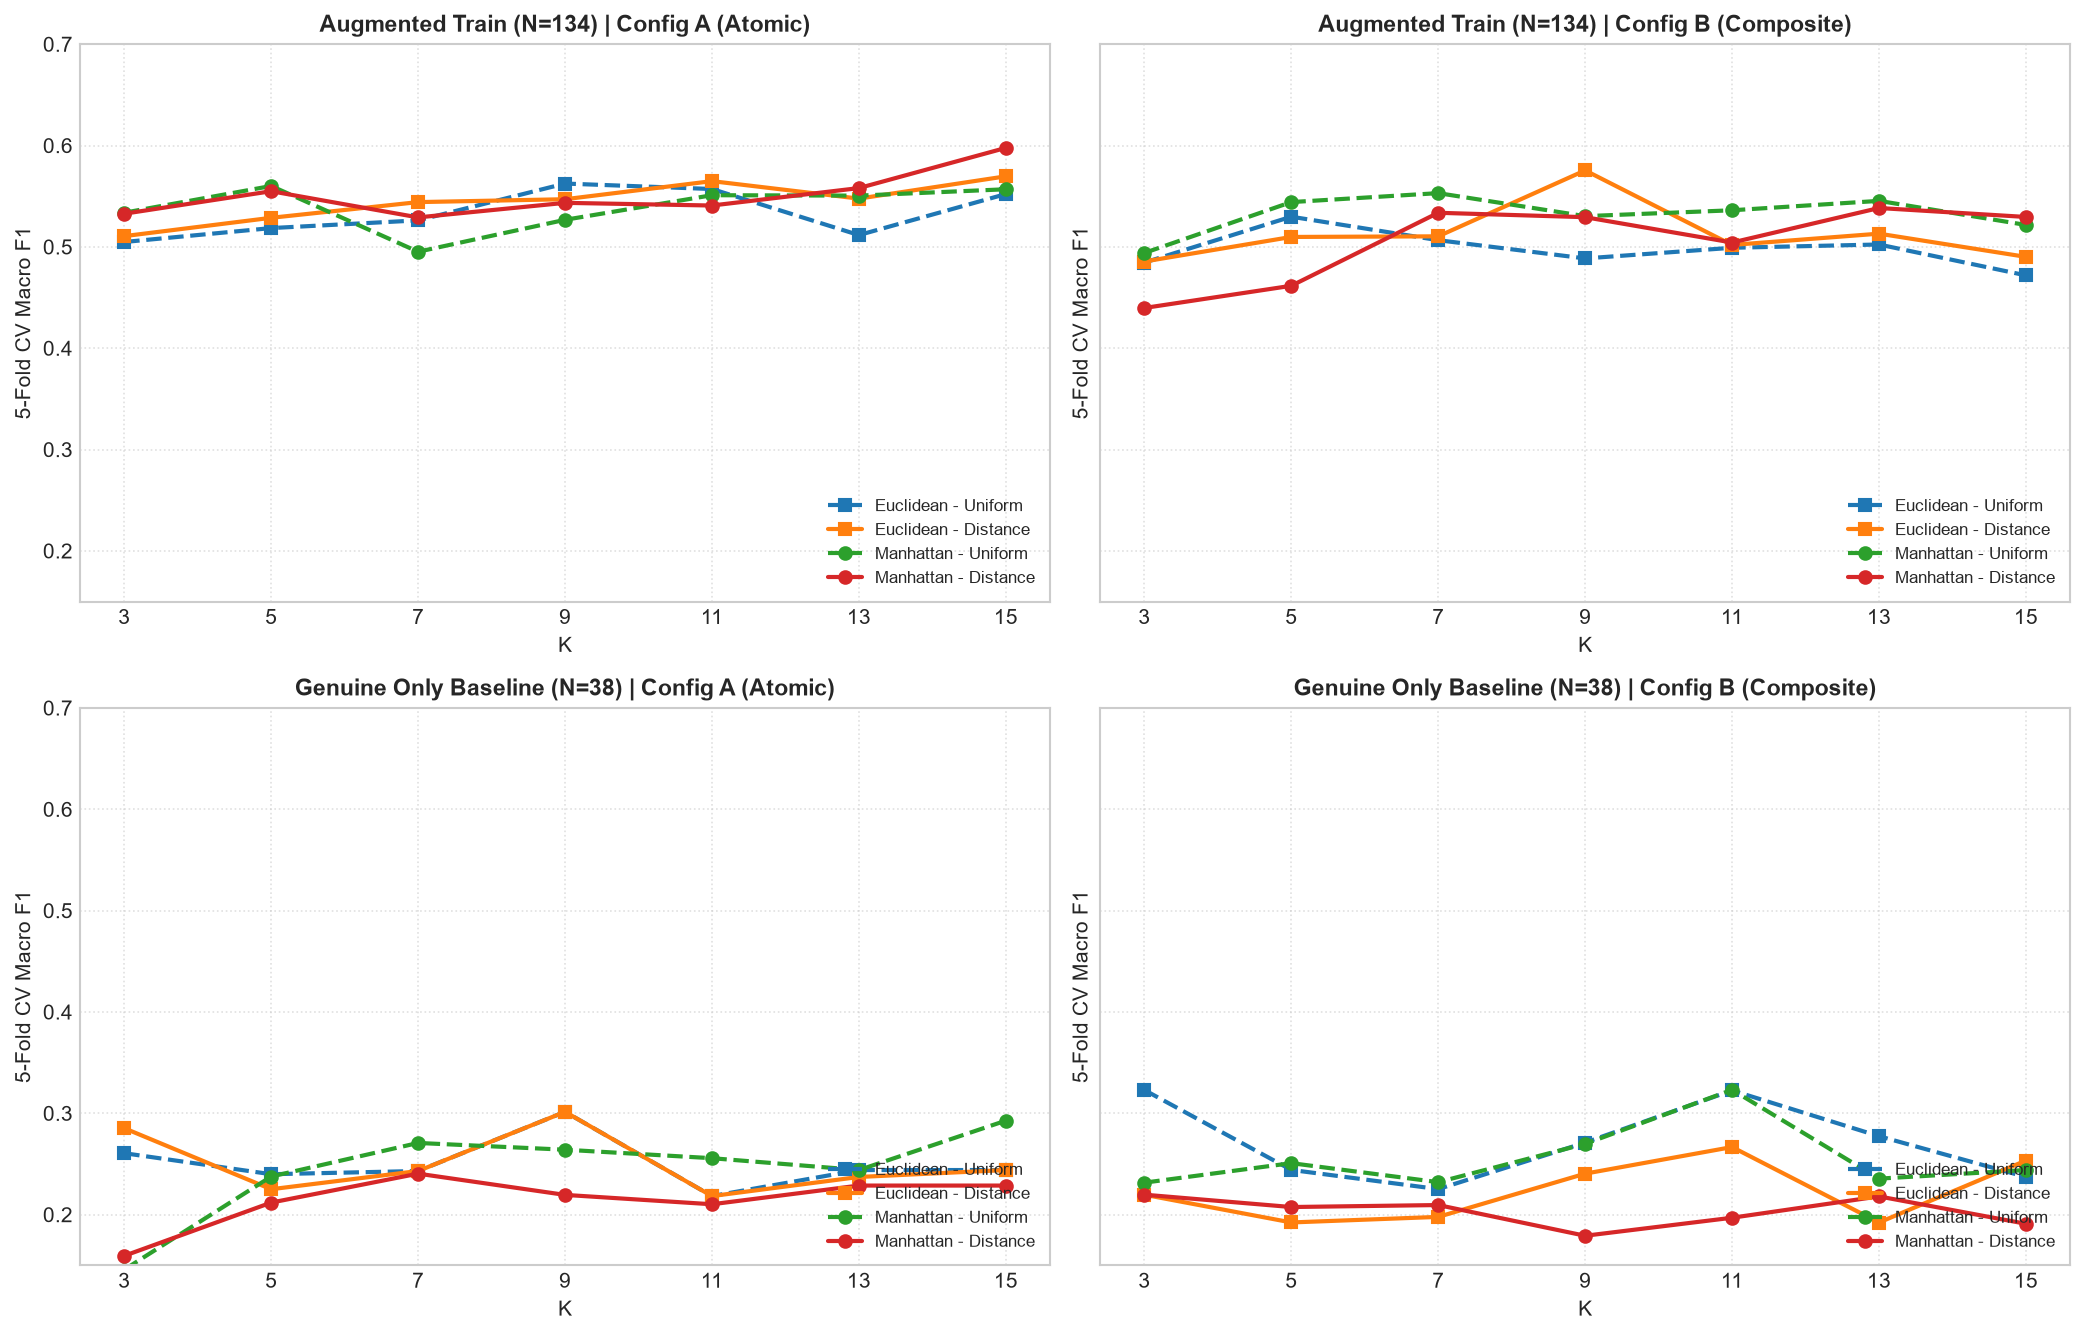

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for idx, exp in enumerate(experiments):
    cv_res = pd.DataFrame(trained_models[exp['id']]['grid'].cv_results_)
    ax = axes.flatten()[idx]
    for metric in ['euclidean', 'manhattan']:
        for weight in ['uniform', 'distance']:
            sub = cv_res[(cv_res['param_knn__metric'] == metric) & (cv_res['param_knn__weights'] == weight)].sort_values('param_knn__n_neighbors')
            ax.plot(sub['param_knn__n_neighbors'], sub['mean_test_score'],
                    label=f"{metric.capitalize()} - {weight.capitalize()}",
                    linestyle='-' if weight == 'distance' else '--',
                    marker='o' if metric == 'manhattan' else 's', linewidth=2)
    ax.set_title(exp['name'], fontsize=11, fontweight='bold')
    ax.set_xlabel("K")
    ax.set_ylabel("5-Fold CV Macro F1")
    ax.set_xticks([3, 5, 7, 9, 11, 13, 15])
    ax.set_ylim(0.15, 0.70)
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 3. Holdout Evaluation ($N=16$) & Majority-Class Baseline
Evaluate all 4 tuned pipelines on the untouched genuine holdout benchmark alongside a Majority-Class Baseline (always predicting `Moderate Impact`).

In [5]:
class_names = ['Low Impact', 'Moderate Impact', 'High Impact']
y_test = df_test['impact_encoded'].values
eval_records = []

for exp in experiments:
    m_info = trained_models[exp['id']]
    y_pred = m_info['best_pipe'].predict(df_test[m_info['features']].values)
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    _, _, f1_cls, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2], zero_division=0)
    m_info['y_pred'] = y_pred
    m_info['cm'] = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
    eval_records.append({
        'Model': exp['name'], 'K': m_info['best_params']['knn__n_neighbors'],
        'Metric': m_info['best_params']['knn__metric'], 'Weights': m_info['best_params']['knn__weights'],
        'CV Macro F1': round(m_info['best_score'], 4),
        'Holdout Acc': round(acc, 4), 'Macro F1': round(macro_f1, 4), 'Weighted F1': round(weighted_f1, 4),
        'F1 Low': round(f1_cls[0], 4), 'F1 Mod': round(f1_cls[1], 4), 'F1 High': round(f1_cls[2], 4)
    })

y_pred_maj = np.full_like(y_test, fill_value=1)
_, _, f1_maj, _ = precision_recall_fscore_support(y_test, y_pred_maj, labels=[0, 1, 2], zero_division=0)
eval_records.append({
    'Model': 'Majority-Class Baseline (Always Moderate)', 'K': 'N/A', 'Metric': 'N/A', 'Weights': 'N/A',
    'CV Macro F1': 'N/A', 'Holdout Acc': round(accuracy_score(y_test, y_pred_maj), 4),
    'Macro F1': round(f1_score(y_test, y_pred_maj, average='macro', zero_division=0), 4),
    'Weighted F1': round(f1_score(y_test, y_pred_maj, average='weighted', zero_division=0), 4),
    'F1 Low': round(f1_maj[0], 4), 'F1 Mod': round(f1_maj[1], 4), 'F1 High': round(f1_maj[2], 4)
})
pd.DataFrame(eval_records)

,Model,K,Metric,Weights,CV Macro F1,Holdout Acc,Macro F1,Weighted F1,F1 Low,F1 Mod,F1 High
0,Augmented Train (N=134) | Config A (Atomic),15,manhattan,distance,0.5976,0.6250,0.4091,0.5795,0.0,0.7273,0.5
1,Augmented Train (N=134) | Config B (Composite),9,euclidean,distance,0.5754,0.3125,0.1667,0.3125,0.0,0.5000,0.0
2,Genuine Only Baseline (N=38) | Config A (Atomic),9,euclidean,uniform,0.3014,0.5625,0.2400,0.4500,0.0,0.7200,0.0
3,Genuine Only Baseline (N=38) | Config B (Compo...,11,manhattan,uniform,0.3231,0.6875,0.4000,0.6000,0.0,0.8000,0.4
4,Majority-Class Baseline (Always Moderate),N/A,N/A,N/A,N/A,0.6250,0.2564,0.4808,0.0,0.7692,0.0


<cell>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


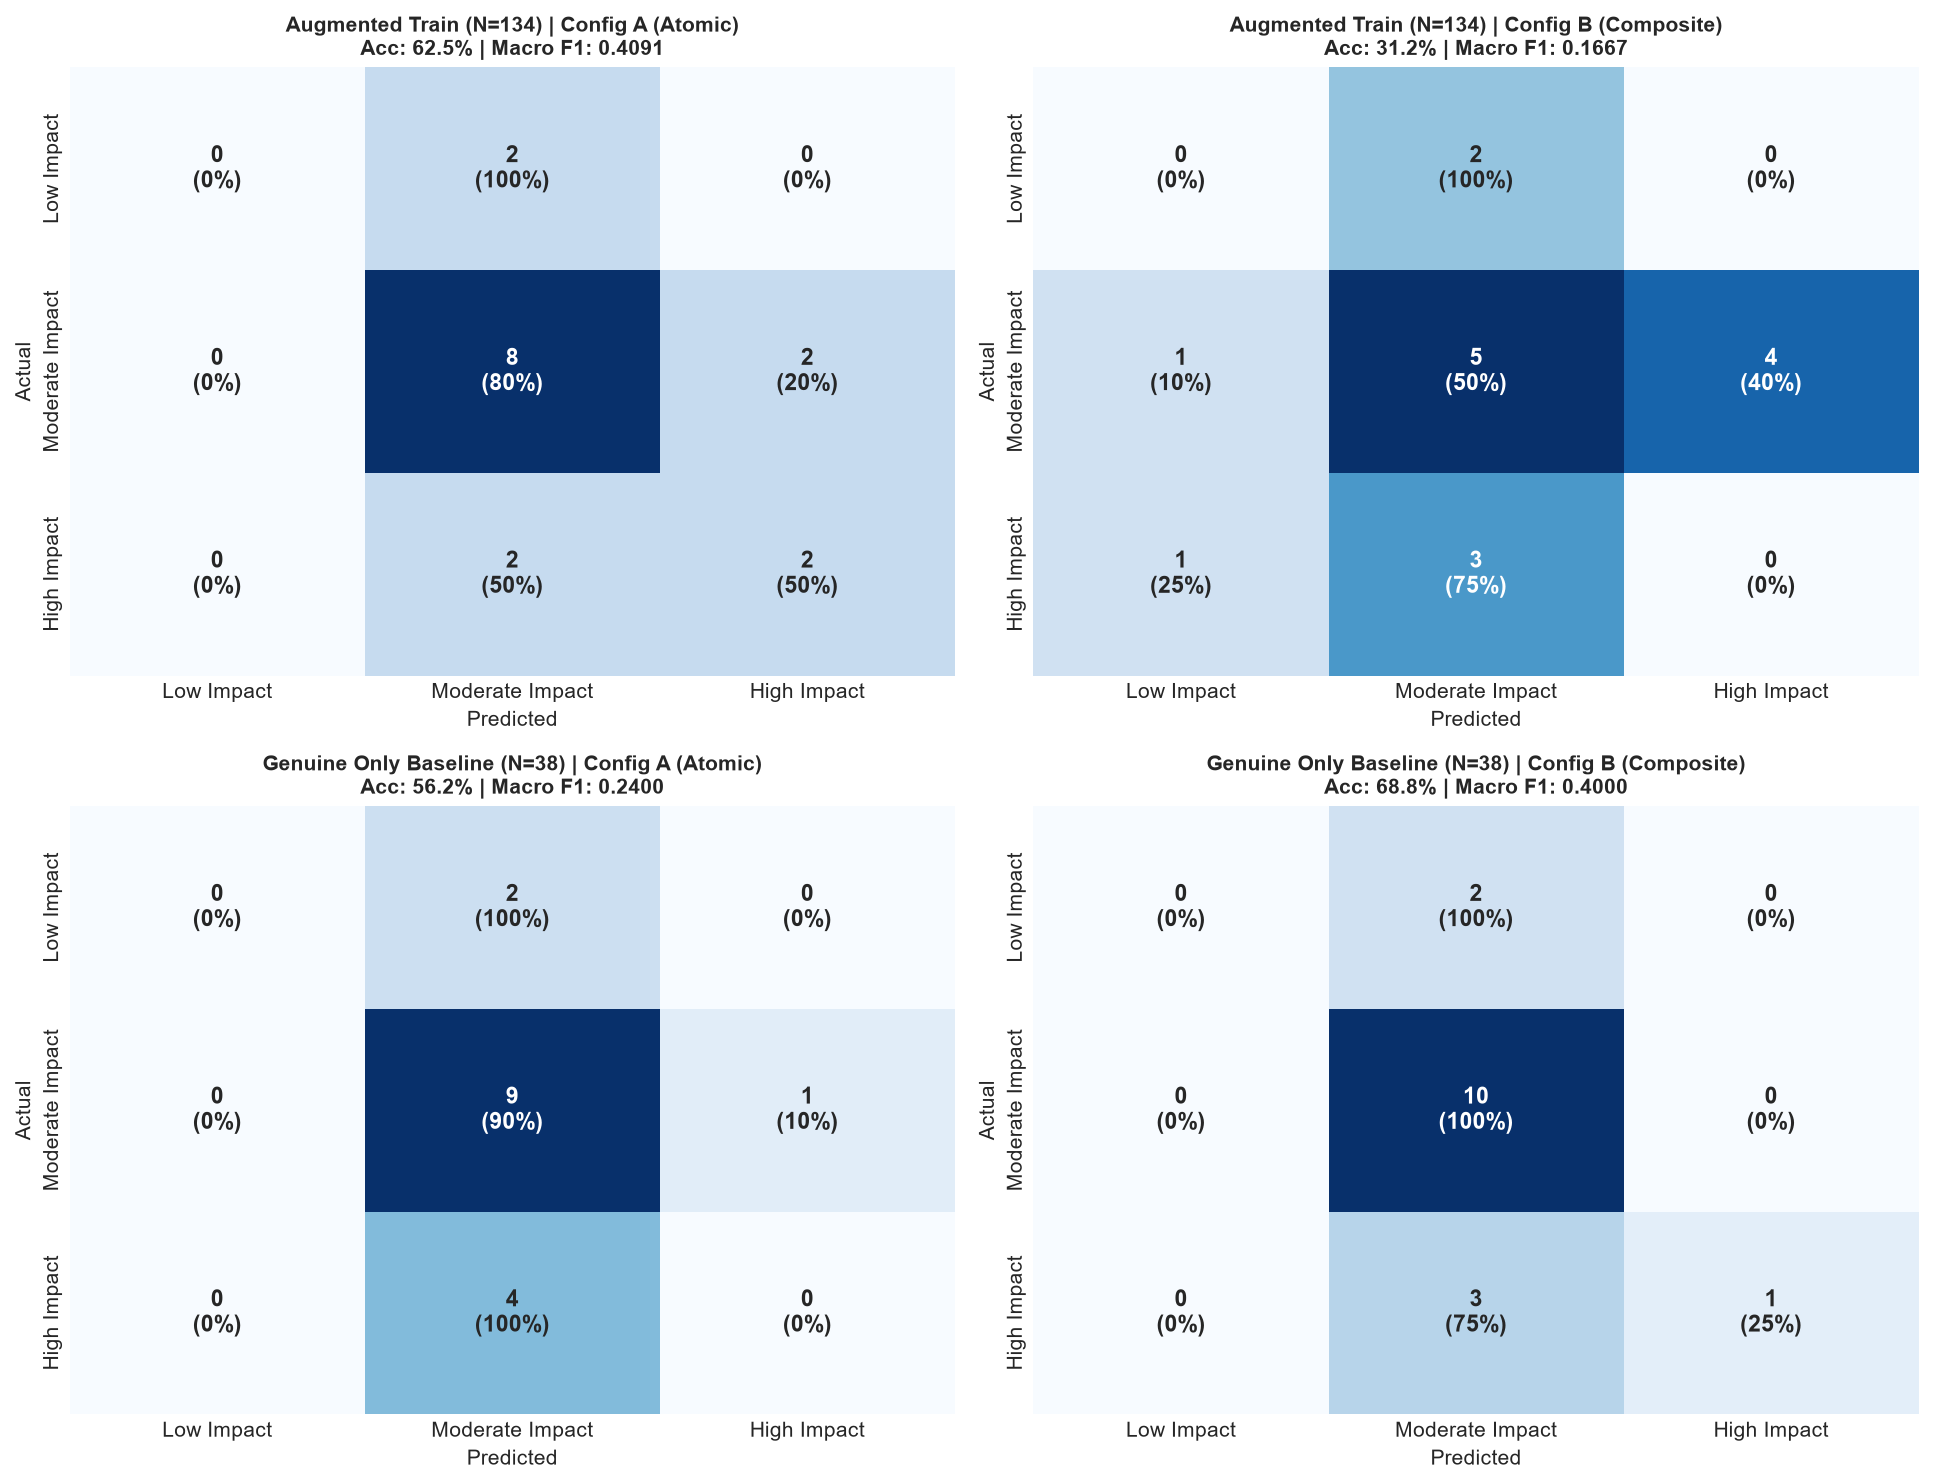

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for idx, exp in enumerate(experiments):
    cm = trained_models[exp['id']]['cm']
    ax = axes.flatten()[idx]
    annot = np.array([[f"{cm[i,j]}\n({(cm[i,j]/cm[i].sum()*100 if cm[i].sum()>0 else 0):.0f}%)" for j in range(3)] for i in range(3)])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax, annot_kws={'size': 11, 'weight': 'bold'})
    rec = eval_records[idx]
    ax.set_title(f"{exp['name']}\nAcc: {rec['Holdout Acc']:.1%} | Macro F1: {rec['Macro F1']:.4f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

<cell>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


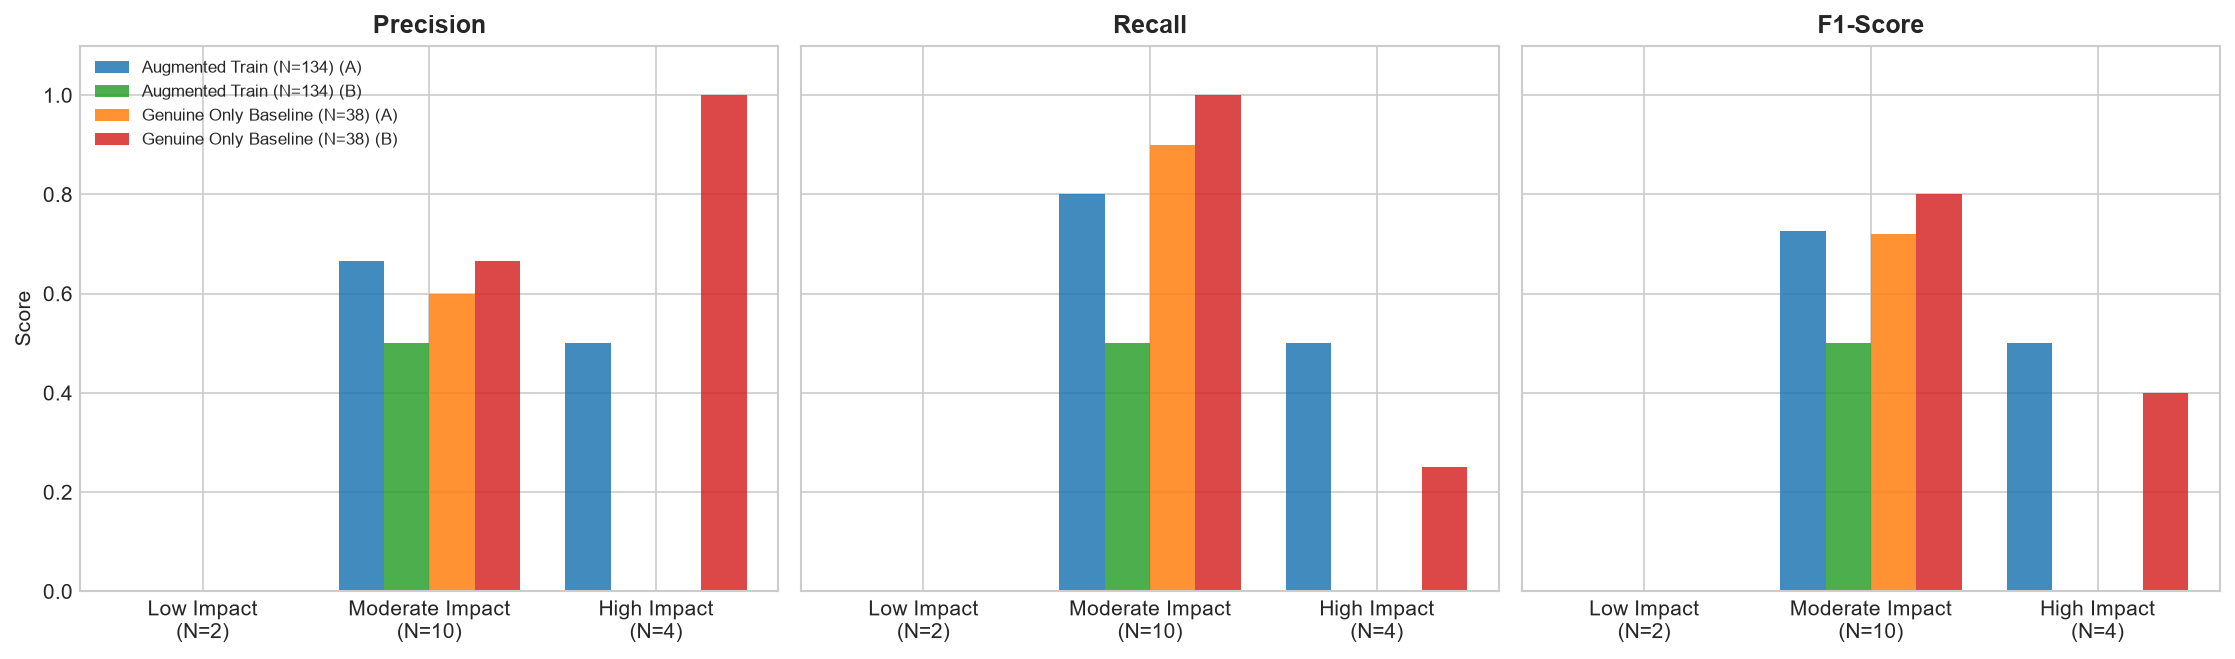

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
x = np.arange(3)
bar_w = 0.2
for m_idx, m_name in enumerate(['Precision', 'Recall', 'F1-Score']):
    ax = axes[m_idx]
    for e_idx, exp in enumerate(experiments):
        p_c, r_c, f1_c, _ = precision_recall_fscore_support(y_test, trained_models[exp['id']]['y_pred'], labels=[0, 1, 2], zero_division=0)
        vals = [p_c, r_c, f1_c][m_idx]
        ax.bar(x + (e_idx - 1.5) * bar_w, vals, width=bar_w,
               label=exp['name'].split('|')[0].strip() + f" ({'A' if 'Atomic' in exp['name'] else 'B'})",
               color=exp['color'], alpha=0.85)
    ax.set_title(m_name, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}\n(N={s})" for c, s in zip(class_names, [2, 10, 4])])
    ax.set_ylim(0, 1.1)
    if m_idx == 0:
        ax.set_ylabel("Score")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Illustrative 2D PCA Decision Boundaries
Scaler and PCA are fitted strictly on training data and applied to the 16 holdout points (`o` = correct, `X` = misclassified). Quantitative evaluation above uses the full feature space.

<cell>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


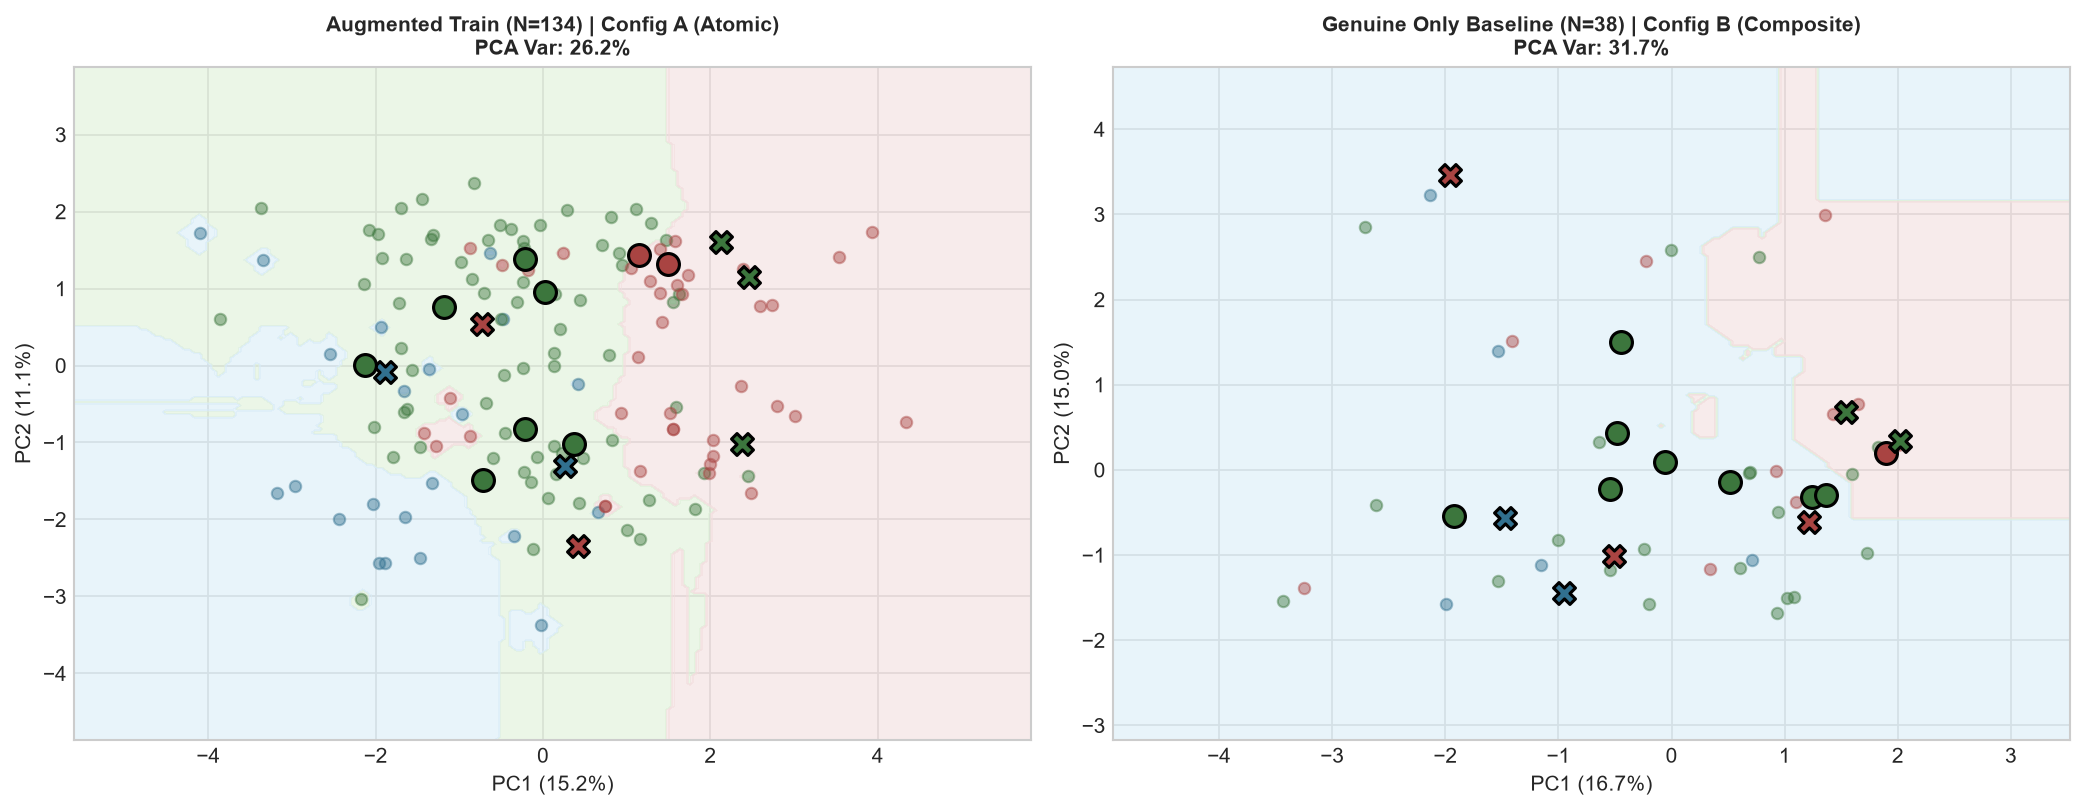

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for i, exp_id in enumerate(['aug_config_a', 'gen_config_b']):
    ax = axes[i]
    m_info = trained_models[exp_id]
    sc = StandardScaler()
    X_tr_sc = sc.fit_transform(m_info['X_tr'])
    X_te_sc = sc.transform(df_test[m_info['features']].values)
    pca = PCA(n_components=2, random_state=SEED)
    X_tr_p = pca.fit_transform(X_tr_sc)
    X_te_p = pca.transform(X_te_sc)
    knn_2d = KNeighborsClassifier(
        n_neighbors=m_info['best_params']['knn__n_neighbors'],
        weights=m_info['best_params']['knn__weights'],
        metric=m_info['best_params']['knn__metric']
    ).fit(X_tr_p, m_info['y_tr'])
    xx, yy = np.meshgrid(np.linspace(X_tr_p[:,0].min()-1.5, X_tr_p[:,0].max()+1.5, 200),
                         np.linspace(X_tr_p[:,1].min()-1.5, X_tr_p[:,1].max()+1.5, 200))
    Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=matplotlib.colors.ListedColormap(['#d9edf7', '#dff0d8', '#f2dede']), alpha=0.6)
    colors = ['#31708f', '#3c763d', '#a94442']
    for c_val, c_name in enumerate(class_names):
        m_tr = (m_info['y_tr'] == c_val)
        ax.scatter(X_tr_p[m_tr, 0], X_tr_p[m_tr, 1], color=colors[c_val], alpha=0.45, s=30, label=f"Train: {c_name}")
    y_pred_2d = knn_2d.predict(X_te_p)
    for j in range(len(y_test)):
        ax.scatter(X_te_p[j, 0], X_te_p[j, 1], color=colors[y_test[j]],
                   marker='o' if y_pred_2d[j] == y_test[j] else 'X', s=110, edgecolors='black', linewidths=1.5, zorder=5)
    ax.set_title(f"{m_info['name']}\nPCA Var: {pca.explained_variance_ratio_.sum():.1%}", fontsize=10, fontweight='bold')
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

## 5. Key KNN Takeaways
- **CV vs. Holdout:** Synthetic augmentation boosted internal CV Macro F1 on Config A ($0.5976$ vs. $0.3014$), but did **not** consistently improve genuine holdout generalization. Genuine-Only Config B achieved the highest holdout accuracy ($68.75\%$, Macro F1 = $0.4000$), while Augmented Config A achieved $62.50\%$ (Macro F1 = $0.4091$) and Augmented Config B dropped to $31.25\%$.
- **Majority-Class Baseline:** Always predicting `Moderate Impact` yields $62.50\%$ accuracy (Macro F1 = $0.2564$), confirming accuracy alone is insufficient on this imbalanced 16-record test set.
- **Zero Low Impact Recall ($0.0\%$):** Both `Low Impact` holdout records were misclassified as `Moderate Impact` due to class imbalance and overlapping device-usage profiles once direct distraction items (Q6–Q8) are excluded.
- **Distance Metric:** Manhattan distance ($L_1$) performed best in Augmented Config A and Genuine Config B on this dataset, though this is an empirical finding specific to these configurations rather than a universal claim.